# Indexación y búsqueda vectorial eficiente con LangChain y FAISS

La búsqueda por vecinos más cercanos recupera documentos cuyos *embeddings* están próximos al vector de una consulta. Este notebook usa **LangChain como interfaz común** para representar documentos, generar embeddings, construir almacenes vectoriales y recuperar resultados. **FAISS** actúa como motor numérico interno y permite cambiar la estructura del índice sin cambiar el contrato de búsqueda de LangChain.

Se comparan cuatro almacenes `FAISS` de LangChain sobre el mismo corpus:

- `IndexFlatIP`: búsqueda exacta y referencia de calidad;
- `IndexHNSWFlat`: grafo jerárquico aproximado;
- `IndexIVFFlat`: particionado en listas con vectores completos;
- `IndexIVFPQ`: particionado y Product Quantization.

Con $N$ vectores de dimensión $d$, la búsqueda exacta cuesta $O(Nd)$. SIMD y las operaciones vectorizadas reducen constantes, pero no eliminan el crecimiento lineal. Los índices ANN evitan examinar toda la colección y producen distintos compromisos entre recall, latencia, memoria y construcción.


## Entorno y configuración

`requirements.txt` fija un entorno reproducible. El valor predeterminado de 50.000 noticias permite observar diferencias reales sin exigir una estación de trabajo. `MAX_DOCUMENTS` puede reducirse para una ejecución rápida o elevarse hasta 120.000. Los embeddings se guardan en disco y se reutilizan mientras no cambien el modelo, la muestra o la semilla.


In [1]:
import sys

if sys.version_info[:2] != (3, 11):
    raise RuntimeError(
        f"Este notebook requiere Python 3.11; el kernel actual usa {sys.version.split()[0]}. "
        "Cierra Jupyter y abre el notebook con el iniciador incluido en la carpeta."
    )

print(f"Python correcto: {sys.version.split()[0]}")


Python correcto: 3.11.15


In [3]:
%pip install -q -r requirements.txt



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
from pathlib import Path
import hashlib
import time
import warnings

import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import load_dataset
from IPython.display import display
warnings.filterwarnings(
    "ignore",
    message=r"`langchain-community` is being sunset.*",
    category=DeprecationWarning,
)
from langchain_community.docstore.in_memory import InMemoryDocstore
from langchain_community.vectorstores import FAISS
from langchain_community.vectorstores.utils import DistanceStrategy
from langchain_core.documents import Document
from langchain_community.embeddings import Model2vecEmbeddings
minishlab/potion-retrieval-32M
SEED = 42
MAX_DOCUMENTS = 50_000
EMBEDDING_MODEL = "minishlab/potion-retrieval-32M"
TOP_K = 10
BENCHMARK_REPETITIONS = 7

CACHE_DIR = Path("cache_vector_search")
CACHE_DIR.mkdir(exist_ok=True)
np.random.seed(SEED)


/home/mario/.pyenv/versions/ebis-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Corpus real como documentos de LangChain

AG News reúne titulares y descripciones en inglés de cuatro áreas: mundo, deportes, negocios y ciencia/tecnología. Sus consultas semánticas son interpretables y su escala hace visible el trabajo que ahorra ANN.

Cada noticia se convierte en un `Document` de LangChain. El texto vive en `page_content`; la categoría y el identificador estable se conservan en `metadata`. Esta separación permite aplicar después filtros, trazabilidad o integración con una cadena RAG sin alterar el índice.


In [5]:
dataset = load_dataset("fancyzhx/ag_news", split="train")
sample_size = min(MAX_DOCUMENTS, len(dataset))
dataset = dataset.shuffle(seed=SEED).select(range(sample_size))

label_names = ["World", "Sports", "Business", "Sci/Tech"]
corpus = pd.DataFrame({
    "text": [" ".join(text.split()) for text in dataset["text"]],
    "label_id": dataset["label"],
})
corpus = corpus[corpus["text"].str.len() > 0].reset_index(drop=True)
corpus["category"] = corpus["label_id"].map(dict(enumerate(label_names)))

documents = [
    Document(
        id=str(row.Index),
        page_content=row.text,
        metadata={"corpus_id": row.Index, "category": row.category},
    )
    for row in corpus.itertuples()
]

print(f"Documentos: {len(documents):,}")
display(corpus[["category", "text"]].head(5))


Generating test split: 100%|██████████| 7600/7600 [00:00<00:00, 223230.95 examples/s]


Documentos: 50,000


,category,text
0,World,Bangladesh paralysed by strikes Opposition act...
1,Sports,Desiring Stability Redskins coach Joe Gibbs ex...
2,World,Will Putin #39;s Power Play Make Russia Safer?...
3,Sci/Tech,U2 pitches for Apple New iTunes ads airing dur...
4,World,S African TV in beheading blunder Public broad...


## Embeddings mediante la integración de LangChain

`Model2vecEmbeddings` implementa el contrato `Embeddings` de LangChain y ejecuta el modelo estático `minishlab/potion-retrieval-32M`, optimizado para recuperación. Produce 512 componentes, no necesita PyTorch ni ONNX y codifica texto mediante operaciones ligeras sobre embeddings de tokens. `embed_documents` procesa el corpus; `embed_query` conserva la misma interfaz para búsquedas posteriores.

Los vectores se normalizan por L2. Por ello, similitud coseno y producto escalar inducen el mismo orden. Para sustituir el modelo local por OpenAI, Google u otro proveedor solo se reemplaza el objeto `embedding_model`; los almacenes y retrievers mantienen su interfaz. La dimensión del índice debe coincidir con la del nuevo modelo.


In [6]:
embedding_model = Model2vecEmbeddings(EMBEDDING_MODEL)

cache_key = hashlib.sha256(
    f"{EMBEDDING_MODEL}|{len(documents)}|{SEED}".encode()
).hexdigest()[:12]
embedding_path = CACHE_DIR / f"ag_news_langchain_{cache_key}.npy"

if embedding_path.exists():
    embeddings = np.load(embedding_path, mmap_mode="r")
    if embeddings.shape[0] != len(documents):
        raise ValueError("La caché no coincide con el corpus seleccionado.")
    print(f"Embeddings cargados desde {embedding_path}")
else:
    embeddings = np.asarray(
        embedding_model.embed_documents([doc.page_content for doc in documents]),
        dtype=np.float32,
    )
    embeddings /= np.linalg.norm(embeddings, axis=1, keepdims=True).clip(min=1e-12)
    np.save(embedding_path, embeddings)
    embeddings = np.load(embedding_path, mmap_mode="r")
    print(f"Embeddings guardados en {embedding_path}")

N_DOCUMENTS, VECTOR_DIMENSION = embeddings.shape
print(f"Matriz: {embeddings.shape}; float32: {embeddings.nbytes / 2**20:.1f} MiB")


Fetching 10 files: 100%|██████████| 10/10 [00:28<00:00,  2.84s/it]


Embeddings guardados en cache_vector_search/ag_news_langchain_ef19630e238c.npy
Matriz: (50000, 512); float32: 97.7 MiB


## Un mismo contrato LangChain para índices diferentes

LangChain separa tres piezas:

1. el modelo de embeddings;
2. el índice FAISS que resuelve la búsqueda vectorial;
3. el `Docstore` que devuelve documentos y metadatos.

La función siguiente envuelve cualquier índice FAISS ya poblado en el mismo `VectorStore`. Todas las búsquedas del notebook pasan por `similarity_search_with_score_by_vector` o por un `Retriever` de LangChain. Se usan vectores de consulta precalculados para que los benchmarks midan el índice y no el modelo.


In [7]:
document_map = {str(i): doc for i, doc in enumerate(documents)}
index_to_docstore_id = {i: str(i) for i in range(N_DOCUMENTS)}
shared_docstore = InMemoryDocstore(document_map)

def as_langchain_vector_store(faiss_index):
    return FAISS(
        embedding_function=embedding_model,
        index=faiss_index,
        docstore=shared_docstore,
        index_to_docstore_id=index_to_docstore_id.copy(),
        distance_strategy=DistanceStrategy.MAX_INNER_PRODUCT,
    )

def search_by_vector(vector_store, query_vector, k=TOP_K):
    results = vector_store.similarity_search_with_score_by_vector(
        query_vector.tolist(), k=k
    )
    ids = np.array([doc.metadata["corpus_id"] for doc, _ in results], dtype=np.int64)
    scores = np.array([score for _, score in results], dtype=np.float32)
    return ids, scores

def benchmark_store(vector_store, query_matrix, repetitions=BENCHMARK_REPETITIONS):
    measurements = []
    last_results = None
    for _ in range(repetitions):
        start = time.perf_counter()
        last_results = [search_by_vector(vector_store, query) for query in query_matrix]
        measurements.append((time.perf_counter() - start) * 1_000 / len(query_matrix))
    return {
        "median_ms_per_query": float(np.median(measurements)),
        "mean_ms_per_query": float(np.mean(measurements)),
        "results": last_results,
    }

def serialized_size_mib(index):
    return faiss.serialize_index(index).nbytes / 2**20

def ranking_table(query_text, ids, scores):
    result = corpus.loc[np.asarray(ids), ["category", "text"]].copy()
    result.insert(0, "score", np.asarray(scores))
    result.insert(0, "rank", np.arange(1, len(result) + 1))
    result.insert(0, "query", query_text)
    return result.reset_index(drop=True)


## Consultas y baseline exacto

`IndexFlatIP` almacena todos los vectores y calcula el producto escalar contra cada uno. No requiere entrenamiento ni una estructura auxiliar: es una referencia exacta y transparente. FAISS vectoriza el cálculo, pero sigue puntuando $N$ documentos por consulta.


In [8]:
queries = [
    "diplomatic negotiations between countries after an armed conflict",
    "a football team wins an international championship",
    "central bank interest rates and their effect on markets",
    "a new spacecraft mission explores another planet",
    "a technology company launches a new mobile device",
    "quarterly earnings and a corporate acquisition",
]
query_embeddings = np.asarray(
    [embedding_model.embed_query(query) for query in queries],
    dtype=np.float32,
)
query_embeddings /= np.linalg.norm(query_embeddings, axis=1, keepdims=True).clip(min=1e-12)

exact_index = faiss.IndexFlatIP(VECTOR_DIMENSION)
exact_index.add(np.asarray(embeddings))
exact_store = as_langchain_vector_store(exact_index)

_ = search_by_vector(exact_store, query_embeddings[0])
exact_benchmark = benchmark_store(exact_store, query_embeddings)
exact_ground_truth = [ids for ids, _ in exact_benchmark["results"]]

for query_text, (ids, scores) in zip(queries[:3], exact_benchmark["results"][:3]):
    display(ranking_table(query_text, ids, scores).head(5))

pd.DataFrame([{
    "method": "Exact",
    "median_ms_per_query": exact_benchmark["median_ms_per_query"],
    "candidates_per_query": N_DOCUMENTS,
}])


,query,rank,score,category,text
0,diplomatic negotiations between countries afte...,1,0.497322,World,Full Sudanese peace talks get off to a shaky s...
1,diplomatic negotiations between countries afte...,2,0.495587,World,"UN Envoy Says 10,000 Peacekeepers Needed for S..."
2,diplomatic negotiations between countries afte...,3,0.492105,World,Full Sudanese peace talks get off to a shaky s...
3,diplomatic negotiations between countries afte...,4,0.479631,World,Sudan's main foes say peace deal imminent (AFP...
4,diplomatic negotiations between countries afte...,5,0.478636,World,Sudan #39;s other humanitarian crisis The coun...


,query,rank,score,category,text
0,a football team wins an international champion...,1,0.494568,Sports,Wins Tough to Find The revamped ACC is one of ...
1,a football team wins an international champion...,2,0.461161,Sports,Ten teams line up for 2005 F1 season Formula O...
2,a football team wins an international champion...,3,0.453620,Sports,It #39;s USC and Oklahoma Even in a year when ...
3,a football team wins an international champion...,4,0.437977,Sports,"BCS Makes Changes To Ranking System Dallas, TX..."
4,a football team wins an international champion...,5,0.434818,Sports,The Steelers try to knock off their second unb...


,query,rank,score,category,text
0,central bank interest rates and their effect o...,1,0.642792,Business,ECB leaves interest rates unchanged European C...
1,central bank interest rates and their effect o...,2,0.637101,Business,No change to interest rates seen The central b...
2,central bank interest rates and their effect o...,3,0.622746,Business,Update 4: European Central Bank Keeps Rates Un...
3,central bank interest rates and their effect o...,4,0.605978,Business,China's Central Bank Hikes Interest Rate BEIJI...
4,central bank interest rates and their effect o...,5,0.604249,Business,"NZ Dollar Gains, Bonds Fall After Central Bank..."


,method,median_ms_per_query,candidates_per_query
0,Exact,7.759819,50000


## ANN y Recall@k

ANN aproxima la selección de candidatos: evita regiones o nodos que parecen poco prometedores. La calidad se mide contra el almacén exacto:

$$\operatorname{Recall@k}(A,E)=\frac{|A_k\cap E_k|}{k}$$

$A_k$ es el conjunto aproximado y $E_k$ el top-$k$ exacto. La media sobre consultas cuantifica cuánto se aproxima el índice al ranking exacto de estos embeddings; no mide por sí sola la relevancia semántica del modelo.


In [9]:
def recall_at_k(approximate_ids, exact_ids, k=TOP_K):
    return len(set(approximate_ids[:k]) & set(exact_ids[:k])) / k

def mean_recall_at_k(approximate_results, exact_results, k=TOP_K):
    return float(np.mean([
        recall_at_k(approx_ids, exact_ids, k)
        for (approx_ids, _), exact_ids in zip(approximate_results, exact_results)
    ]))

assert recall_at_k(np.arange(TOP_K), np.arange(TOP_K)) == 1.0


## HNSW dentro del VectorStore de LangChain

HNSW representa cada vector como un nodo de un grafo de proximidad. Sus capas superiores son escasas y permiten saltos largos; la capa base contiene conexiones locales. La consulta entra arriba, avanza hacia nodos más similares y desciende para refinar la región. Esta navegación *coarse-to-fine* evita puntuar toda la colección.

- `M` controla aproximadamente las conexiones por nodo: más conectividad suele mejorar recall, memoria y coste de construcción.
- `efConstruction` controla la amplitud usada al insertar nodos.
- `efSearch` controla cuántos candidatos mantiene la búsqueda; puede variarse sin reconstruir.

El objeto expuesto al resto del código sigue siendo `FAISS`, el VectorStore de LangChain. Solo se modifica la configuración del motor encapsulado.


In [10]:
HNSW_M = 16
HNSW_EF_CONSTRUCTION = 200
HNSW_EF_VALUES = [10, 25, 50, 100, 200]

hnsw_index = faiss.IndexHNSWFlat(
    VECTOR_DIMENSION, HNSW_M, faiss.METRIC_INNER_PRODUCT
)
hnsw_index.hnsw.efConstruction = HNSW_EF_CONSTRUCTION

start = time.perf_counter()
hnsw_index.add(np.asarray(embeddings))
hnsw_build_seconds = time.perf_counter() - start
hnsw_store = as_langchain_vector_store(hnsw_index)
hnsw_size_mib = serialized_size_mib(hnsw_index)

hnsw_rows = []
for ef_search in HNSW_EF_VALUES:
    hnsw_index.hnsw.efSearch = max(ef_search, TOP_K)
    _ = search_by_vector(hnsw_store, query_embeddings[0])
    benchmark = benchmark_store(hnsw_store, query_embeddings)
    hnsw_rows.append({
        "method": "HNSW",
        "configuration": f"efSearch={ef_search}",
        "recall_at_k": mean_recall_at_k(benchmark["results"], exact_ground_truth),
        "median_ms_per_query": benchmark["median_ms_per_query"],
        "candidates_per_query": np.nan,
        "size_mib": hnsw_size_mib,
        "build_seconds": hnsw_build_seconds,
    })

hnsw_benchmarks = pd.DataFrame(hnsw_rows)
display(hnsw_benchmarks)


,method,configuration,recall_at_k,median_ms_per_query,candidates_per_query,size_mib,build_seconds
0,HNSW,efSearch=10,0.933333,0.128540,NaN,104.537287,10.262353
1,HNSW,efSearch=25,0.950000,0.164877,NaN,104.537287,10.262353
2,HNSW,efSearch=50,0.983333,0.242920,NaN,104.537287,10.262353
3,HNSW,efSearch=100,1.000000,0.383865,NaN,104.537287,10.262353
4,HNSW,efSearch=200,1.000000,0.628689,NaN,104.537287,10.262353


## IVF: particionar antes de buscar

IVF aprende un cuantizador grueso con `nlist` centroides. Cada vector se asigna a una lista invertida. Para buscar se seleccionan los `nprobe` centroides más próximos y solo se puntúan los vectores de esas listas.

Un `nprobe` pequeño ahorra comparaciones, pero puede perder vecinos al otro lado de una frontera. Aumentarlo mejora normalmente recall y latencia hasta aproximarse al barrido completo. `IndexIVFFlat` conserva vectores `float32`, por lo que la aproximación procede de las listas visitadas, no de la similitud calculada sobre sus candidatos.


In [11]:
N_LISTS = int(np.clip(round(np.sqrt(N_DOCUMENTS)), 64, 512))
IVF_NPROBE_VALUES = sorted(set([1, 2, 4, 8, 16, 32, min(64, N_LISTS)]))

ivf_quantizer = faiss.IndexFlatIP(VECTOR_DIMENSION)
ivf_index = faiss.IndexIVFFlat(
    ivf_quantizer, VECTOR_DIMENSION, N_LISTS, faiss.METRIC_INNER_PRODUCT
)

start = time.perf_counter()
ivf_index.train(np.asarray(embeddings))
ivf_index.add(np.asarray(embeddings))
ivf_build_seconds = time.perf_counter() - start
ivf_store = as_langchain_vector_store(ivf_index)
ivf_size_mib = serialized_size_mib(ivf_index)

def ivf_candidate_count(index, query_vector, nprobe):
    _, list_ids = index.quantizer.search(
        np.asarray(query_vector, dtype=np.float32).reshape(1, -1), nprobe
    )
    return int(sum(index.invlists.list_size(int(i)) for i in list_ids[0] if i >= 0))

list_sizes = np.array([ivf_index.invlists.list_size(i) for i in range(N_LISTS)])
print(f"Listas: {N_LISTS}; construcción: {ivf_build_seconds:.2f} s")
print(f"Elementos por lista: media={list_sizes.mean():.1f}, mínimo={list_sizes.min()}, máximo={list_sizes.max()}")


Listas: 224; construcción: 2.37 s
Elementos por lista: media=223.2, mínimo=22, máximo=717


In [16]:
ivf_rows = []
for nprobe in IVF_NPROBE_VALUES:
    ivf_index.nprobe = nprobe
    _ = search_by_vector(ivf_store, query_embeddings[0])
    benchmark = benchmark_store(ivf_store, query_embeddings)
    mean_candidates = np.mean([
        ivf_candidate_count(ivf_index, query, nprobe) for query in query_embeddings
    ])
    ivf_rows.append({
        "method": "IVF",
        "configuration": f"nprobe={nprobe}",
        "recall_at_k": mean_recall_at_k(benchmark["results"], exact_ground_truth),
        "median_ms_per_query": benchmark["median_ms_per_query"],
        "candidates_per_query": mean_candidates,
        "size_mib": ivf_size_mib,
        "build_seconds": ivf_build_seconds,
    })

ivf_benchmarks = pd.DataFrame(ivf_rows)
display(ivf_benchmarks)


,method,configuration,recall_at_k,median_ms_per_query,candidates_per_query,size_mib,build_seconds
0,IVF,nprobe=1,0.500000,0.550151,364.166667,98.477061,2.366849
1,IVF,nprobe=2,0.816667,0.672922,697.333333,98.477061,2.366849
2,IVF,nprobe=4,0.850000,1.031399,1131.000000,98.477061,2.366849
3,IVF,nprobe=8,0.900000,1.208793,2147.000000,98.477061,2.366849
4,IVF,nprobe=16,0.933333,0.819038,3912.166667,98.477061,2.366849
5,IVF,nprobe=32,0.983333,1.357616,7492.333333,98.477061,2.366849
6,IVF,nprobe=64,1.000000,2.222382,14815.000000,98.477061,2.366849


## Product Quantization mediante IVF-PQ

PQ resuelve un problema complementario: comprime cada vector. Divide sus $d$ componentes en `m` subvectores, aprende un codebook por subespacio y almacena identificadores de centroides en lugar de `float32`. Con `nbits=8`, cada identificador ocupa un byte.

Durante la búsqueda, la consulta permanece sin comprimir y FAISS precalcula tablas de distancia contra los codebooks. La puntuación de cada código se obtiene con accesos y sumas: *asymmetric distance computation*. `IndexIVFPQ` combina dos aproximaciones: IVF decide qué listas visitar y PQ aproxima los vectores de esas listas.

Con 384 dimensiones, el vector original ocupa 1.536 bytes. Con `m=12`, el código principal ocupa 12 bytes por documento, más centroides, codebooks e identificadores compartidos.


In [17]:
PQ_M = 16
PQ_NBITS = 8
PQ_TRAIN_SIZE = min(30_000, N_DOCUMENTS)
PQ_NPROBE_VALUES = [value for value in [4, 16, 64] if value <= N_LISTS]

if VECTOR_DIMENSION % PQ_M != 0:
    raise ValueError("VECTOR_DIMENSION debe ser divisible por PQ_M.")

rng = np.random.default_rng(SEED)
pq_training_ids = rng.choice(N_DOCUMENTS, size=PQ_TRAIN_SIZE, replace=False)
pq_quantizer = faiss.IndexFlatIP(VECTOR_DIMENSION)
ivfpq_index = faiss.IndexIVFPQ(
    pq_quantizer,
    VECTOR_DIMENSION,
    N_LISTS,
    PQ_M,
    PQ_NBITS,
    faiss.METRIC_INNER_PRODUCT,
)

start = time.perf_counter()
ivfpq_index.train(np.asarray(embeddings)[pq_training_ids])
ivfpq_index.add(np.asarray(embeddings))
ivfpq_build_seconds = time.perf_counter() - start
ivfpq_store = as_langchain_vector_store(ivfpq_index)
ivfpq_size_mib = serialized_size_mib(ivfpq_index)

display(pd.DataFrame([
    {"representation": "IndexFlatIP", "size_mib": serialized_size_mib(exact_index)},
    {"representation": "IndexIVFPQ", "size_mib": ivfpq_size_mib},
]))


,representation,size_mib
0,IndexFlatIP,97.656293
1,IndexIVFPQ,2.083790


In [18]:
ivfpq_rows = []
for nprobe in PQ_NPROBE_VALUES:
    ivfpq_index.nprobe = nprobe
    _ = search_by_vector(ivfpq_store, query_embeddings[0])
    benchmark = benchmark_store(ivfpq_store, query_embeddings)
    mean_candidates = np.mean([
        ivf_candidate_count(ivfpq_index, query, nprobe) for query in query_embeddings
    ])
    ivfpq_rows.append({
        "method": "IVF-PQ",
        "configuration": f"nprobe={nprobe}, m={PQ_M}, nbits={PQ_NBITS}",
        "recall_at_k": mean_recall_at_k(benchmark["results"], exact_ground_truth),
        "median_ms_per_query": benchmark["median_ms_per_query"],
        "candidates_per_query": mean_candidates,
        "size_mib": ivfpq_size_mib,
        "build_seconds": ivfpq_build_seconds,
    })

ivfpq_benchmarks = pd.DataFrame(ivfpq_rows)
display(ivfpq_benchmarks)


,method,configuration,recall_at_k,median_ms_per_query,candidates_per_query,size_mib,build_seconds
0,IVF-PQ,"nprobe=4, m=16, nbits=8",0.333333,0.242888,1211.500000,2.08379,9.60915
1,IVF-PQ,"nprobe=16, m=16, nbits=8",0.333333,0.266956,4246.833333,2.08379,9.60915
2,IVF-PQ,"nprobe=64, m=16, nbits=8",0.333333,0.506072,15217.000000,2.08379,9.60915


## Recuperación idiomática con LangChain

Los benchmarks anteriores usan la variante por vector para excluir la codificación de la latencia. En una aplicación, el acceso habitual parte del texto. `as_retriever()` transforma cualquier almacén en un `Runnable` de LangChain; el mismo retriever puede conectarse a una cadena RAG, herramientas o agentes.


In [19]:
ivf_index.nprobe = 16
retriever = ivf_store.as_retriever(search_kwargs={"k": 5})
retrieved_documents = retriever.invoke(queries[3])

display(pd.DataFrame([
    {
        "category": doc.metadata["category"],
        "corpus_id": doc.metadata["corpus_id"],
        "text": doc.page_content,
    }
    for doc in retrieved_documents
]))


,category,corpus_id,text
0,Sci/Tech,22140,Red Planet Bound: Mars Reconnaissance Orbiter ...
1,Sci/Tech,30158,New Data Strengthen Mars Life Evidence Finding...
2,Sci/Tech,48499,NASA Extends Mars Odyssey Orbiter Mission (AP)...
3,Sci/Tech,13430,US-European Mission To Solve Mystery Of Saturn...
4,Sci/Tech,26408,Still No Answers From Mars on Beagle 2 (AP) AP...


## Comparación final

Cada fila es un punto de operación. HNSW cambia la exploración del grafo con `efSearch`; IVF e IVF-PQ cambian listas y candidatos con `nprobe`. El tamaño se obtiene serializando el índice FAISS encapsulado. FAISS no expone cuántos nodos visita HNSW, por lo que esa celda queda vacía.

La latencia corresponde al VectorStore de LangChain y excluye el cálculo del embedding de consulta. Las cifras dependen del hardware, corpus, modelo y bibliotecas; la relación entre puntos es más informativa que un valor aislado.


In [20]:
exact_row = pd.DataFrame([{
    "method": "Exact",
    "configuration": "IndexFlatIP",
    "recall_at_k": 1.0,
    "median_ms_per_query": exact_benchmark["median_ms_per_query"],
    "candidates_per_query": float(N_DOCUMENTS),
    "size_mib": serialized_size_mib(exact_index),
    "build_seconds": 0.0,
}])

comparison = pd.concat(
    [exact_row, hnsw_benchmarks, ivf_benchmarks, ivfpq_benchmarks],
    ignore_index=True,
).sort_values(["method", "median_ms_per_query"]).reset_index(drop=True)

display(comparison.round({
    "recall_at_k": 3,
    "median_ms_per_query": 3,
    "candidates_per_query": 0,
    "size_mib": 1,
    "build_seconds": 2,
}))


,method,configuration,recall_at_k,median_ms_per_query,candidates_per_query,size_mib,build_seconds
0,Exact,IndexFlatIP,1.000,7.760,50000.0,97.7,0.00
1,HNSW,efSearch=10,0.933,0.129,NaN,104.5,10.26
2,HNSW,efSearch=25,0.950,0.165,NaN,104.5,10.26
3,HNSW,efSearch=50,0.983,0.243,NaN,104.5,10.26
4,HNSW,efSearch=100,1.000,0.384,NaN,104.5,10.26
5,HNSW,efSearch=200,1.000,0.629,NaN,104.5,10.26
6,IVF,nprobe=1,0.500,0.550,364.0,98.5,2.37
7,IVF,nprobe=2,0.817,0.673,697.0,98.5,2.37
8,IVF,nprobe=16,0.933,0.819,3912.0,98.5,2.37
9,IVF,nprobe=4,0.850,1.031,1131.0,98.5,2.37


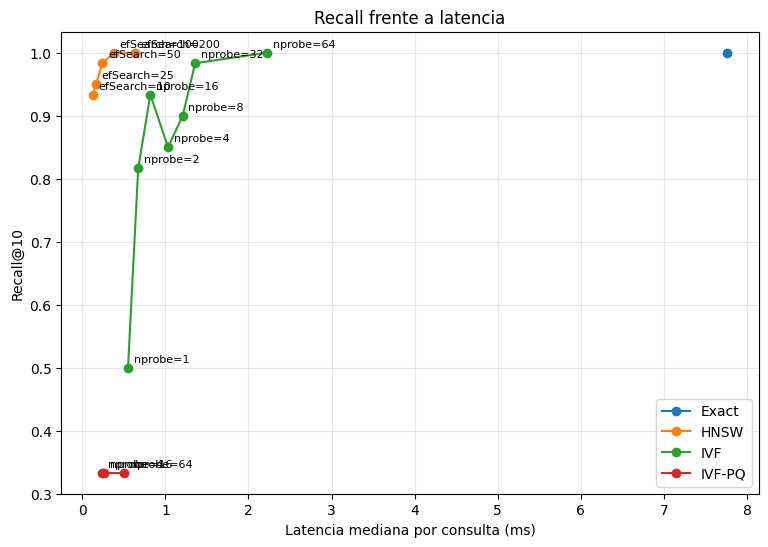

In [21]:
fig, ax = plt.subplots(figsize=(9, 6))
for method, group in comparison.groupby("method", sort=False):
    ax.plot(group["median_ms_per_query"], group["recall_at_k"], marker="o", label=method)
    for _, row in group.iterrows():
        if method != "Exact":
            ax.annotate(
                row["configuration"].split(",")[0],
                (row["median_ms_per_query"], row["recall_at_k"]),
                xytext=(4, 4), textcoords="offset points", fontsize=8,
            )

ax.set_xlabel("Latencia mediana por consulta (ms)")
ax.set_ylabel(f"Recall@{TOP_K}")
ax.set_title("Recall frente a latencia")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()


## Inspección cualitativa

Recall mide coincidencia de identificadores, pero documentos casi equivalentes pueden intercambiar posiciones alrededor de $k$. La comparación siguiente pasa por los cuatro VectorStores de LangChain y permite examinar esas diferencias.


In [22]:
query_number = 3
query_text = queries[query_number]
query_vector = query_embeddings[query_number]

hnsw_index.hnsw.efSearch = 50
ivf_index.nprobe = 16
ivfpq_index.nprobe = 16

for method, store in [
    ("Exact", exact_store),
    ("HNSW", hnsw_store),
    ("IVF", ivf_store),
    ("IVF-PQ", ivfpq_store),
]:
    ids, scores = search_by_vector(store, query_vector, k=5)
    display(ranking_table(query_text, ids, scores).assign(method=method))


,query,rank,score,category,text,method
0,a new spacecraft mission explores another planet,1,0.632748,Sci/Tech,Red Planet Bound: Mars Reconnaissance Orbiter ...,Exact
1,a new spacecraft mission explores another planet,2,0.590887,Sci/Tech,New Data Strengthen Mars Life Evidence Finding...,Exact
2,a new spacecraft mission explores another planet,3,0.583803,Sci/Tech,NASA Extends Mars Odyssey Orbiter Mission (AP)...,Exact
3,a new spacecraft mission explores another planet,4,0.574148,Sci/Tech,US-European Mission To Solve Mystery Of Saturn...,Exact
4,a new spacecraft mission explores another planet,5,0.567241,Sci/Tech,Still No Answers From Mars on Beagle 2 (AP) AP...,Exact


,query,rank,score,category,text,method
0,a new spacecraft mission explores another planet,1,0.632748,Sci/Tech,Red Planet Bound: Mars Reconnaissance Orbiter ...,HNSW
1,a new spacecraft mission explores another planet,2,0.590887,Sci/Tech,New Data Strengthen Mars Life Evidence Finding...,HNSW
2,a new spacecraft mission explores another planet,3,0.583803,Sci/Tech,NASA Extends Mars Odyssey Orbiter Mission (AP)...,HNSW
3,a new spacecraft mission explores another planet,4,0.574148,Sci/Tech,US-European Mission To Solve Mystery Of Saturn...,HNSW
4,a new spacecraft mission explores another planet,5,0.567241,Sci/Tech,Still No Answers From Mars on Beagle 2 (AP) AP...,HNSW


,query,rank,score,category,text,method
0,a new spacecraft mission explores another planet,1,0.632748,Sci/Tech,Red Planet Bound: Mars Reconnaissance Orbiter ...,IVF
1,a new spacecraft mission explores another planet,2,0.590887,Sci/Tech,New Data Strengthen Mars Life Evidence Finding...,IVF
2,a new spacecraft mission explores another planet,3,0.583803,Sci/Tech,NASA Extends Mars Odyssey Orbiter Mission (AP)...,IVF
3,a new spacecraft mission explores another planet,4,0.574148,Sci/Tech,US-European Mission To Solve Mystery Of Saturn...,IVF
4,a new spacecraft mission explores another planet,5,0.567241,Sci/Tech,Still No Answers From Mars on Beagle 2 (AP) AP...,IVF


,query,rank,score,category,text,method
0,a new spacecraft mission explores another planet,1,0.569090,Sci/Tech,US-European Mission To Solve Mystery Of Saturn...,IVF-PQ
1,a new spacecraft mission explores another planet,2,0.566022,Sci/Tech,Cassini gets altitude adjustment The Cassini-H...,IVF-PQ
2,a new spacecraft mission explores another planet,3,0.558553,Sci/Tech,Water on Mars: More Evidences The Mars Explora...,IVF-PQ
3,a new spacecraft mission explores another planet,4,0.549952,Sci/Tech,Cassini-Huygens discovers two new Saturnian mo...,IVF-PQ
4,a new spacecraft mission explores another planet,5,0.543596,Sci/Tech,New Data Strengthen Mars Life Evidence Finding...,IVF-PQ


## Decisiones de diseño

- **Escala y tasa de consultas.** `IndexFlatIP` es simple y exacto, pero crece linealmente con la colección.
- **SLA de latencia.** HNSW suele ofrecer latencia baja y alto recall; IVF expresa el presupuesto mediante listas y candidatos.
- **Recall objetivo.** Debe medirse con consultas representativas y un baseline exacto.
- **Memoria.** HNSW añade aristas; IVFFlat conserva vectores; IVFPQ reduce la huella a cambio de error de cuantización.
- **Construcción y actualización.** HNSW inserta nodos; IVF y PQ requieren entrenamiento y pueden necesitar reentrenamiento si cambia la distribución.
- **Abstracción.** LangChain mantiene estable la interfaz de recuperación y el tipo `Document`; FAISS conserva el control fino del índice.
- **Operación.** Filtros, borrados, persistencia, concurrencia y aceleración pueden dominar la elección.

No existe un índice universalmente mejor. Una evaluación sólida fija restricciones, mide una familia de configuraciones y elige un punto de la frontera recall–latencia–memoria que satisfaga el sistema.
